---
---
# INTRODUCTION TO CLASSIFICATION

---
---

## ROADMAP: where we've been, and where we're going

* We are studying **predictive modeling**: given what we know about a *new* unit ($x$), what should we expect for its response ($y$)?

* In the previous lecture the response was **numeric**, which makes it a **regression** problem. We predicted global temperature anomalies using

    * **k-nearest neighbours**: *average* the responses of the $k$ most similar units,

  and we learned to evaluate predictions using **residuals**, the **MSR** and the **MAR**. We also learned the `scikit-learn` recipe: 
  
    * **create $\rightarrow$ fit $\rightarrow$ predict**.

**Today we change the type of response.** What if we want to predict a **category** instead of a number? That's a **classification** problem.

| If the response variable $y$ is... | ...the problem is called | Example |
|---|---|---|
| **numeric** | **regression** | How warm will 2030 be, compared to normal? |
| **categorical** | **classification** | Is this tumour benign or malignant? |

Recall our first lecture where we explored several motivating data science applications. In turns out that several of them were classification problems: 

* *Is this star's light curve hiding a planet?*
* *Is this satellite pixel a wildfire hotspot?* 
* *Will this student drop out?*
* *Is this email spam?*

**Binary classification** is the simplest and most common case: there are exactly **two** possible classes (yes/no, spam/not spam, sick/healthy). We code them as **1** and **0**. Some problems have more than two classes (for example, recognizing a handwritten digit from 0 to 9, or identifying which of three penguin species a bird belongs to). That's called **multi-class classification**. Much of what we do here extends to more than two classes, but *in this course* we'll just focus on the binary case.

> **A note on terminology:** In binary classification, we call the class coded **1** the **positive class**, and the class coded **0** the **negative class**. "Positive" doesn't mean "good". It just means *the outcome we are trying to detect*. For a medical test, "positive" is *has the disease*. In the example we consider here, "positive" will be *a malignant (cancerous) tumour*.

---

### 🗣 ACTIVITY: Classify the problem

For each question, say whether it is **regression**, **binary classification**, or **multi-class classification**. For the binary ones, what would the *positive class* be?

> 1. Will a customer cancel their subscription next month?
> 2. How many minutes will a delivery take?
> 3. Which of {cat, dog, rabbit} is in this photo?
> 4. Does this credit card transaction look fraudulent?
> 5. How much will the price of this house increase next year?

<details>
<summary><b>Discussion Notes</b></summary>

1. **Binary classification.** Positive class: *cancels*.
2. **Regression.** The response (minutes) is a number.
3. **Multi-class classification.** There are three classes.
4. **Binary classification.** Positive class: *fraudulent*.
5. **Regression.** The response (a price change) is a number.

</details>

---
---

## The Data: Diagnosing Breast Cancer

In the previous *Is it prediction?* activity, we considered this question:

> *Given a tumour's cell area and perimeter, is it benign or malignant?*

Today we analyze data that addresses exactly this question.

When a patient has a lump in their breast, one way for doctors to learn more about the mass is a **fine needle aspiration (FNA)**: a thin needle is used to withdraw a few cells from the lump. The cells are examined under a microscope to decide whether the mass is

* **benign** (B): not cancerous, or
* **malignant** (M): cancerous.

In the early 1990s, a team at the University of Wisconsin ([led by Dr. William Wolberg, a surgeon, together with computer scientists Nick Street and Olvi Mangasarian](https://scixplorer.org/abs/1993SPIE.1905..861S/abstract)) wondered whether a computer could help. They [digitized microscope images of FNA samples](https://www.researchgate.net/publication/361082777/figure/fig1/AS:11431281386394903@1745065429288/Digitalized-image-of-the-Wisconsin-breast-dataset-27.tif) and used image analysis software to outline each **cell nucleus** and **measure its shape**: how big is it, how smooth is its outline, how irregular is it?

**The question:**

> **Can we predict whether a breast mass is malignant or benign, using measurements of its cell nuclei?**

This is a **binary classification** problem, and it's *predictive*: we want to predict the diagnosis for a *new* patient from measurements we can compute automatically.

### About the Data

The data we'll analyze is stored in the `wdbc.csv` file made available [here on GitHub](https://github.com/ntstevens/DATSC101/blob/main/data/wdbc.csv). It is the **Wisconsin Diagnostic Breast Cancer** data set, publicly available from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic).

There are $n=569$ patients. For each one, the following is recorded:

* `ID`: an identification number for the patient's sample.
* `Class`: the diagnosis: `M` (malignant) or `B` (benign).
* Ten measurements of the cell nuclei in the digitized image, each *averaged* over the nuclei in the image: 

| Measurement | What it describes (for a cell nucleus) |
|---|---|
| `Radius` | Average distance from the centre of the nucleus to points on its outline. |
| `Texture` | Variation in the gray-scale values of the pixels inside the nucleus. |
| `Perimeter` | The length of the outline of the nucleus. |
| `Area` | The area enclosed by the outline. |
| `Smoothness` | Local variation in the lengths of the radii. |
| `Compactness` | The ratio of squared perimeter and area. |
| `Concavity` | Severity of the *indentations* in the outline (parts that curve inward). |
| `Concave_Points` | Number of such indentations. |
| `Symmetry` | How symmetric the nucleus is. |
| `Fractal_Dimension` | How "rough" or coastline-like the outline is. |

Today we'll focus on just **two** of them: `Perimeter` first, and then `Concavity`.

**A note on the scale of the measurements.** The measurements in this file have been **standardized**: each one has been rescaled so that it has an average of **0** and a standard deviation of **1**. So, a `Perimeter` of $0$ is an *average* perimeter, a `Perimeter` of $+1$ is one standard deviation *above* average, and a `Perimeter` of $-1$ is one standard deviation *below* average. A negative perimeter does **not** mean a nucleus with negative length; it just means *smaller than average*. This is why the values range from about $-2$ to $+4$.

In [2]:
# Load necessary libraries
import pandas as pd
import numpy as np
import plotly.express as px

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [3]:
cancer = pd.read_csv('https://raw.githubusercontent.com/ntstevens/DATSC101/refs/heads/main/data/wdbc.csv')
cancer

,ID,Class,Radius,Texture,Perimeter,Area,Smoothness,Compactness,Concavity,Concave_Points,Symmetry,Fractal_Dimension
0,842302,M,1.096100,-2.071512,1.268817,0.983510,1.567087,3.280628,2.650542,2.530249,2.215566,2.253764
1,842517,M,1.828212,-0.353322,1.684473,1.907030,-0.826235,-0.486643,-0.023825,0.547662,0.001391,-0.867889
2,84300903,M,1.578499,0.455786,1.565126,1.557513,0.941382,1.052000,1.362280,2.035440,0.938859,-0.397658
3,84348301,M,-0.768233,0.253509,-0.592166,-0.763792,3.280667,3.399917,1.914213,1.450431,2.864862,4.906602
4,84358402,M,1.748758,-1.150804,1.775011,1.824624,0.280125,0.538866,1.369806,1.427237,-0.009552,-0.561956
...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,2.109139,0.720838,2.058974,2.341795,1.040926,0.218868,1.945573,2.318924,-0.312314,-0.930209
565,926682,M,1.703356,2.083301,1.614511,1.722326,0.102368,-0.017817,0.692434,1.262558,-0.217473,-1.057681
566,926954,M,0.701667,2.043775,0.672084,0.577445,-0.839745,-0.038646,0.046547,0.105684,-0.808406,-0.894800
567,927241,M,1.836725,2.334403,1.980781,1.733693,1.524426,3.269267,3.294046,2.656528,2.135315,1.042778


Let's see how many patients are in each class:

In [32]:
cancer["Class"].value_counts()

Class
B    357
M    212
Name: count, dtype: int64

Of the 569 patients, **357 (62.7%) had benign** masses and **212 (37.3%) had malignant** ones.

`scikit-learn` works best when the classes are coded as **numbers**, so, in keeping with our convention, let's create a variable `Malignant` that is `1` for the positive class (malignant) and `0` for the negative class (benign). We use the `.astype(int)` method to convert a boolean column to a binary column with each `True` converting to a `1` and each `False` converting to a `0`.

In [5]:
cancer["Malignant"] = (cancer["Class"] == "M").astype(int)

cancer[["Class", "Malignant", "Perimeter", "Concavity"]]

,Class,Malignant,Perimeter,Concavity
0,M,1,1.268817,2.650542
1,M,1,1.684473,-0.023825
2,M,1,1.565126,1.362280
3,M,1,-0.592166,1.914213
4,M,1,1.775011,1.369806
...,...,...,...,...
564,M,1,2.058974,1.945573
565,M,1,1.614511,0.692434
566,M,1,0.672084,0.046547
567,M,1,1.980781,3.294046


---

### 🗣 ACTIVITY: Problem, Plan, Data

* What is a *unit* in this data set? What is the *response variable*? What is the *explanatory variable* if we want to predict the diagnosis from the perimeter of the cell nuclei?
* Which outcome is the *positive class*?
* What kind of data collection strategy produced this data?
* Suppose a model predicts a patient's mass is benign, but it is actually malignant. Suppose another model predicts malignant, but it is actually benign. What happens to the patient in each case? Which mistake seems worse?

<details>
<summary><b>Discussion Notes</b></summary>

* **Unit:** one patient (more precisely, one breast mass sample). **Response variable:** `Class` (equivalently `Malignant`; binary). **Explanatory variable:** `Perimeter` (numeric).
* **Positive class:** malignant (`Malignant = 1`).
* **Data collection:** observational: researchers did not assign anyone a tumour type; they measured samples from patients and recorded the known diagnosis.
* **Mistakes:** predicting *benign* when the mass is malignant (a **missed cancer**) may delay treatment, with potentially fatal consequences. Predicting *malignant* when the mass is benign (a **false alarm**) causes anxiety and leads to further tests, but the error is eventually caught. Most people would say the missed cancer is worse. **Hold on to this idea**, because it will matter when we measure performance.

</details>

---
---

## Exploring the Data: Perimeter and Diagnosis

We start where we always do, by *looking* at the data. Our explanatory variable `Perimeter`is numeric and our response variable `Class` is categorical, so let's compare the distribution of perimeters in the two groups with overlaid histograms. 

**Note:** previously you've seen overlaid histograms with `plotly.graph_objects` [(see here)](https://plotly.com/python/histograms/#overlaid-histogram). Below you'll see another way, using `px.histogram()` directly.

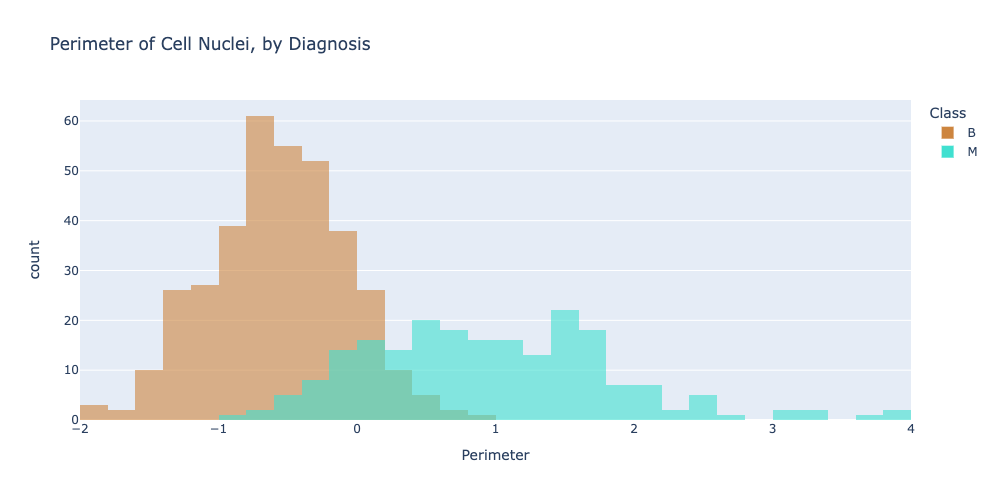

In [34]:
fig = px.histogram(cancer, x = "Perimeter", color = "Class",
                   barmode = "overlay", opacity = 0.6, nbins = 40,
                   color_discrete_map = {"B": "peru", "M": "turquoise"},
                   category_orders = {"Class": ["B", "M"]},
                   title = "Perimeter of Cell Nuclei, by Diagnosis",
                   labels = {"Perimeter":"Perimeter", "count":"Number of patients"},
                   height = 500)
fig.show()

Let's also calculate some numeric summaries of `Perimeter` for each class separately.

In [7]:
cancer.groupby("Class")["Perimeter"].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
B,357.0,-0.571778,0.485923,-1.982759,-0.868309,-0.567474,-0.241534,0.931355
M,212.0,0.962853,0.899406,-0.825921,0.278858,0.914893,1.562039,3.972634


**What do we find?**

* Malignant masses tend to have **larger perimeters**: the average perimeter is about $+0.96$ for malignant masses versus about $-0.57$ for benign ones.
* But the two groups **overlap**. Very small perimeters are almost always benign and very large perimeters are almost always malignant, but in the middle (roughly $-0.5$ to $+0.8$) both diagnoses are common.

Another way to view the same data is to plot the 0/1 response against the explanatory variable:

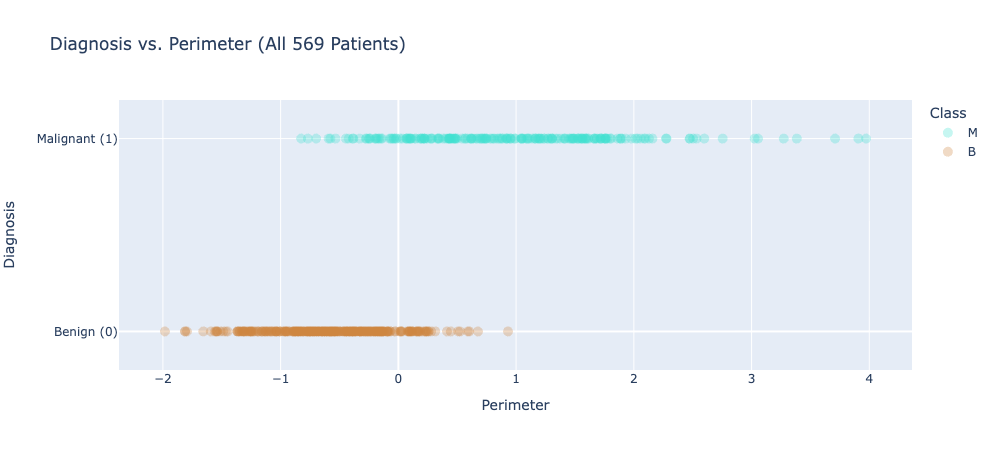

In [8]:
fig = px.scatter(cancer, x = "Perimeter", y = "Malignant", color = "Class",
                 title = "Diagnosis vs. Perimeter (All 569 Patients)",
                 labels = {"Perimeter": "Perimeter", "Malignant": "Diagnosis"},
                 color_discrete_map = {"B": "peru", "M": "turquoise"},
                 opacity = 0.3,
                 height = 450)

fig.update_traces(marker = dict(size = 10))
fig.update_yaxes(tickvals = [0, 1], ticktext = ["Benign (0)", "Malignant (1)"], range = [-0.2, 1.2])

The pattern is the same: benign points (bottom) pile up on the left and malignant points (top) pile up on the right, with a messy region in between.

Now suppose a new patient arrives whose cell nuclei have a perimeter of **0.5** (half a standard deviation above average), right in the messy region... **What diagnosis should we predict?**

Let's build a model that does this.

---
---

## k-Nearest Neighbours for Classification

The k-NN idea is exactly the same as before: **to predict for a new unit, look at the $k$ nearest units in the data.** There's only one thing that needs to change. Previously the neighbours' responses were *numbers*, so we **averaged** them. Now the neighbours' responses are *classes*, and it doesn't make sense to average "benign" and "malignant". Instead we let the neighbours **vote**:

> **k-NN classification:** find the $k$ nearest neighbours of the new unit. Predict the class that is **most common** among those neighbours: the **majority vote**.

**Note:** To avoid ties, we usually choose $k$ to be an *odd* number.

### k-NN by Hand: A Perimeter of 0.5

Let's classify the new patient with perimeter 0.5, using $k = 5$ neighbours.

**Step 1.** Compute the distance between each patient's `Perimeter` and 0.5. 

In [9]:
new_perimeter = 0.5

by_hand = cancer.copy()
by_hand["Distance"] = (by_hand["Perimeter"] - new_perimeter).abs()
by_hand[["Perimeter", "Class", "Malignant", "Distance"]]

,Perimeter,Class,Malignant,Distance
0,1.268817,M,1,0.768817
1,1.684473,M,1,1.184473
2,1.565126,M,1,1.065126
3,-0.592166,M,1,1.092166
4,1.775011,M,1,1.275011
...,...,...,...,...
564,2.058974,M,1,1.558974
565,1.614511,M,1,1.114511
566,0.672084,M,1,0.172084
567,1.980781,M,1,1.480781


**Step 2.** Identify the five patients with the closest `Perimeter` values.

In [10]:
neighbours = by_hand.sort_values(by = "Distance").head(5)
neighbours[["Perimeter", "Class", "Malignant", "Distance"]]

,Perimeter,Class,Malignant,Distance
75,0.499238,M,1,0.000762
406,0.507468,B,0,0.007468
509,0.486891,M,1,0.013109
13,0.482776,M,1,0.017224
259,0.482776,M,1,0.017224


**Step 3.** Count the votes.

In [11]:
neighbours["Class"].value_counts()

Class
M    4
B    1
Name: count, dtype: int64

Among the five nearest neighbours of a perimeter of 0.5, **four** were malignant and **one** was benign. The majority vote is **malignant**, so the 5-NN prediction is $\hat{y} = 1$.

**Let's recap:**

| Step | What we do |
|:-:|---|
| 1 | Compute the **distance** from the new unit to every unit in the data. |
| 2 | Find the **$k$ nearest** units (the neighbours). |
| 3 | Let the neighbours **vote**: predict the most common class. |

---

### 🗣 DISCUSSION: Does the choice of $k$ matter?

With a partner, discuss:

1. Look at the table of five neighbours above. If we had used $k = 1$, what would the prediction have been?
2. What would happen if we used $k = 569$, the *size of the entire data set*? What would every neighbour vote look like, for *any* new patient?
3. Is there an obviously "correct" choice for $k$?

### 💻 Interactive: Build Your Intuition for k-NN Classification

Before we ask Python to do this for us, let's play with the idea. The app below lets you see how k-NN makes classifications and what happens when you change $k$. Focus on the "1-D: Perimeter" tab for now.

> **If the app doesn't display below**, open it in its own browser tab: [https://nathaniel-t-stevens.shinyapps.io/knn_classification_app/](https://nathaniel-t-stevens.shinyapps.io/knn_classification_app/)

In [12]:
%%html
<div style="text-align: center;">
<iframe src="https://nathaniel-t-stevens.shinyapps.io/knn_classification_app/" width="100%" height="850" frameborder="0"></iframe>
</div>

---
---

## k-NN Classification with `scikit-learn`

Let's now have Python perform these classifications automatically. Again, we turn to `scikit-learn`. Conveniently, the recipe is the same as before: **create $\rightarrow$ fit $\rightarrow$ predict**

But this time, we swap `KNeighborsRegressor` for `KNeighborsClassifier`.

| Step | What it does | Code |
|---|---|---|
| **0. Separate** `X` and `y` | The explanatory variable(s) go in a **data frame** `X`. <br> The response goes in a **series** `y`. | `X = cancer[["Perimeter"]]` <br> `y = cancer["Malignant"]`  |
| **1. Create** the model | Choose a method and its settings (e.g., the value of $k$). | `model = KNeighborsClassifier(n_neighbors = 5)` |
| **2. Fit** the model | Show the model the data so that it can "learn" from it. | `model.fit(X, y)` |
| **3. Predict** | Ask the model for predictions at new explanatory variable values. | `model.predict(new_X)` |

In [13]:
from sklearn.neighbors import KNeighborsClassifier

X = cancer[["Perimeter"]]     # explanatory variable (a data frame: double brackets!)
y = cancer["Malignant"]       # response variable (a series of 0s and 1s)

knn5 = KNeighborsClassifier(n_neighbors = 5)
knn5.fit(X, y)

new_data = pd.DataFrame({"Perimeter": [0.5]})
knn5.predict(new_data)

array([1])

This classification agrees with our by-hand calculation: class **1**, malignant.

As before, we can ask for several predictions at once:

In [14]:
new_data = pd.DataFrame({"Perimeter": [-1.5, -0.5, 0.5, 1.5]})

knn5.predict(new_data)

array([0, 0, 1, 1])

---

#### ACTIVITY 💻: Predict the diagnosis for patients with perimeters of 0 and 1 using $k = 3$ and $k = 25$. 

<details>
<summary><b>Show Solution</b></summary>

```python
new_data = pd.DataFrame({"Perimeter": [0, 1]})

knn3 = KNeighborsClassifier(n_neighbors = 3).fit(X, y)
knn25 = KNeighborsClassifier(n_neighbors = 25).fit(X, y)

print("k = 3:  predicted class =", knn3.predict(new_data))
print("k = 25: predicted class =", knn25.predict(new_data))
```

</details>

---
---

## Measuring Classification Performance

For numeric prediction we measured performance with residuals ($y_i - \hat{y}_i$), the MSR and the MAR. Those don't make sense here: the response is a class, and the "difference" between *benign* and *malignant* isn't a number.

Instead, for each unit, we simply ask: **did the model get it right?** And since there are two classes, there are exactly four things that can happen.

### The Confusion Matrix

| | **Predicted: benign** (negative) |**Predicted: malignant** (positive) | 
|---|:-:|:-:|
| **Actual: benign (negative)** | *True Negative (TN)*: predicted benign, and it was. ✅ |*False Positive (FP)*: predicted malignant, but it was benign. ❌ | 
| **Actual: malignant (positive)** | *False Negative (FN)*: predicted benign, but it was malignant. ❌ |*True Positive (TP)*: predicted malignant, and it was. ✅ | 


* The **True** outcomes are the model being **right**; the **False** outcomes are the model being **wrong**.
* The words **Positive/Negative** refer to what the model *predicted*.

Recall the two kinds of mistakes from our earlier activity. They are *very* different in their consequences:

* A **false negative** means the model said *"benign"* when the mass was *malignant*: a **missed cancer**.
* A **false positive** means the model said *"malignant"* when the mass was *benign*: a **false alarm**, which leads to unncessary worry and potential procedures.

Let's compute the confusion matrix for the $k = 5$ model. 
* First we use the model to predict the class for each of the 569 patients
* Then we cross-tabulate predictions against actuals with `confusion_matrix()` from `sklearn.metrics`.

In [36]:
predictions = knn5.predict(X)
predictions

array([1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1,
       0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1,
       1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0,
       0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1,
       1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1,
       0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1,

In [16]:
np.array(y)         # actuals

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1,
       0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1,
       0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1,
       1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0,
       0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1,
       1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1,

In [37]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y, predictions)

pd.DataFrame(cm,
             index = ["Actual: benign", "Actual: malignant"],
             columns = ["Predicted: benign", "Predicted: malignant"])

,Predicted: benign,Predicted: malignant
Actual: benign,342,15
Actual: malignant,33,179


Reading the confusion matrix for the $k = 5$ model:

* **TN = 342**: 342 masses were benign, and the model correctly predicted benign.
* **TP = 179**: 179 masses were malignant, and the model correctly predicted malignant.
* **FP = 15**: 15 benign masses were flagged as malignant (false alarms).
* **FN = 33**: 33 malignant masses were missed.

### Three Performance Measures

From these four counts we compute summary measures:

**Accuracy**: what proportion of *all* predictions were correct?

$$\text{accuracy} = \frac{\text{number of correct predictions}}{\text{total number of predictions}} = \frac{TP + TN}{TP + TN + FP + FN}$$

**Sensitivity** (a.k.a. **true positive rate** or **recall**): of the patients who *actually had a malignant mass*, what proportion did the model identify?

$$\text{sensitivity} = \frac{\text{number of correct positive predictions}}{\text{number of positive observations}}= \frac{TP}{TP + FN}$$

**Specificity** (a.k.a. **true negative rate**): of the patients who *actually had a benign mass*, what proportion did the model correctly clear?

$$\text{specificity} = \frac{\text{number of correct negative predictions}}{\text{number of negative observations}}=\frac{TN}{TN + FP}$$

A helpful way to remember these: 
* **sensitivity** is about how *sensitive* the model is to the thing we're looking for (the positives); 
* **specificity** is about how *specific* the model is, i.e., how well it avoids false alarms on negatives. 

**Note:** Larger values are better for all three of these metrics.

In [39]:
tn, fp, fn, tp = cm.ravel()

accuracy = (tp + tn) / (tp + tn + fp + fn)
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)

print("Accuracy:    ", accuracy)
print("Sensitivity: ", sensitivity)
print("Specificity: ", specificity)

Accuracy:     0.9156414762741653
Sensitivity:  0.8443396226415094
Specificity:  0.957983193277311


So the 5-NN model:

* has an **accuracy of 91.6%**: it gets 521 out of 569 predictions right. That sounds good!
* has a **sensitivity of 84.4%**: it catches about 5 out of 6 malignant masses, but misses about 1 in 6.
* has a **specificity of 95.8%**: it correctly clears most benign masses.

`scikit-learn` also has built-in functions for these:
* accuracy is `accuracy_score()`,
* sensitivity is `recall_score()`, and 
* specificity is `recall_score()` with the *negative* class specified:

In [19]:
from sklearn.metrics import accuracy_score, recall_score

print("Accuracy:   ", accuracy_score(y, predictions))
print("Sensitivity:", recall_score(y, predictions))                  # recall of the positive class
print("Specificity:", recall_score(y, predictions, pos_label = 0))   # recall of the negative class

Accuracy:    0.9156414762741653
Sensitivity: 0.8443396226415094
Specificity: 0.957983193277311


---

#### ✍️ ACTIVITY: Spam, Screening, and Fraud

A spam filter is tested on 1000 emails. The positive class is *spam*. The results are tabulated below.

| | Predicted: spam | Predicted: not spam |
|---|:-:|:-:|
| **Actual: spam** | 80 | 20 |
| **Actual: not spam** | 10 | 890 |

1. Compute the accuracy, sensitivity and specificity.
2. In words, what does a *false positive* mean for a spam filter? What does a *false negative* mean? Which is worse for the user?
3. For *each* of these applications, which measure (sensitivity or specificity) would you prioritize, and why? 

    * (a) screening for a serious but treatable disease;
    * (b) a spam filter 
    * (c) a bank's system that freezes your card when it flags a transaction as fraudulent

<details>
<summary><b>Discussion Notes</b></summary>

1. Accuracy $= (80 + 890)/1000 = 0.97$. Sensitivity $= 80/(80 + 20) = 0.80$. Specificity $= 890/(890 + 10) \approx 0.989$.
2. A **false positive** is a legitimate email sent to the spam folder. A **false negative** is a spam message that lands in your inbox. Most people consider the false positive *worse* (you might miss an important email), so spam filters prioritize **specificity**.
3. (a) **Sensitivity**: missing a sick patient is much worse than a false alarm that a second test can clear up. (b) **Specificity**, as above. (c) *This one is debatable.* A missed fraud (false negative) costs the bank and the customer money, which argues for sensitivity. But a frozen card on a legitimate purchase (false positive) is annoying, and too many false alarms drive customers away. Banks must balance the two.

</details>

---

### A Warning About Accuracy

Let's compute these three measures for k-NN models with a range of values of $k$. We'll write a small **function** to avoid repeating the same code. (Recall: a function is a reusable, self-contained block of code that performs a specific task.)

Here is the general syntax:

<div style="text-align: center;">
  <img src="https://raw.githubusercontent.com/ntstevens/DATSC101/refs/heads/main/images/function_definition.svg" alt="functions" width = 300/>
</div>

In [20]:
def classification_summary(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {"TP": int(tp), "FN": int(fn), "FP": int(fp), "TN": int(tn),
            "Accuracy": float((tp + tn) / (tp + tn + fp + fn)),
            "Sensitivity": float(tp / (tp + fn)),
            "Specificity": float(tn / (tn + fp))}

In [40]:
results = []
for k in [1, 3, 5, 15, 51, 201, 569]:
    model = KNeighborsClassifier(n_neighbors = k).fit(X, y)
    summary = classification_summary(y, model.predict(X))
    summary["k"] = k
    results.append(summary)

pd.DataFrame(results).set_index("k").round(3)

,TP,FN,FP,TN,Accuracy,Sensitivity,Specificity
k,,,,,,,
1,208,4,3,354,0.988,0.981,0.992
3,178,34,10,347,0.923,0.840,0.972
5,179,33,15,342,0.916,0.844,0.958
15,170,42,17,340,0.896,0.802,0.952
51,160,52,10,347,0.891,0.755,0.972
201,156,56,8,349,0.888,0.736,0.978
569,0,212,0,357,0.627,0.000,1.000


Several things stand out:

* **$k = 1$ looks nearly perfect.** When we ask the model to classify a patient who is *in the data*, that patient is their own nearest neighbour, so the model just reads off the answer. (The handful of mistakes happen where a benign and a malignant mass have *exactly* the same perimeter, so one can't tell them apart.) This is the same phenomenon we saw with numeric prediction: a model that has simply memorized the data scores very well on that data. But is a model that memorized the data really a *good predictor*? Keep that question in mind.
* **As $k$ grows, performance deteriorates.** Voting from more neighbours pulls predictions away from each patient's individual diagnosis.
* **Look at $k = 569$.** Now every patient's "neighbours" are the *entire data set*, so every vote comes out the same way: 357 benign vs. 212 malignant. The model predicts **benign for everyone**. Its **sensitivity is 0**: it detected *none* of the 212 cancers! Yet its accuracy is **62.7%**, which doesn't sound *terrible*.
    * It would be reasonable to wonder: *how can a useless model have 62.7% accuracy?* 
    * Because 357 of the 569 patients (62.7%) had benign masses. **A model that *always predicts "benign"* is right 62.7% of the time.**

In [22]:
# The accuracy of a "model" that always predicts the most common class (benign)
(y == 0).mean()

0.6274165202108963

This is a crucial lesson about **imbalanced classes** (when one class is more common than the other):

> **Accuracy can be misleading.** Always compare accuracy to the "always predict the most common class" baseline, and always look at **sensitivity and specificity** too.

Here, the 5-NN model's accuracy of 91.6% is impressive *compared to the 62.7% baseline*, not compared to 0%. And notice that the baseline model's sensitivity of 0 tells the real story, in a way that its accuracy hides.

---
---

## k-NN Classification with Two (or more) Explanatory Variables

With perimeter alone, the two diagnoses overlap in the middle (perimeters of roughly $-0.5$ to $+0.8$), and that's where our model makes most of its mistakes. **Could a second measurement help us tell the two groups apart in that region?**

Let's bring in `Concavity`, a measure of how deeply the outline of a nucleus *indents* inward. Irregular, indented outlines are often associated with cancerous cells. Larger values indicate a more irregular outline.

Now we have **two** explanatory variables, so our scatter plot has one variable on each axis, and we colour the points by diagnosis.

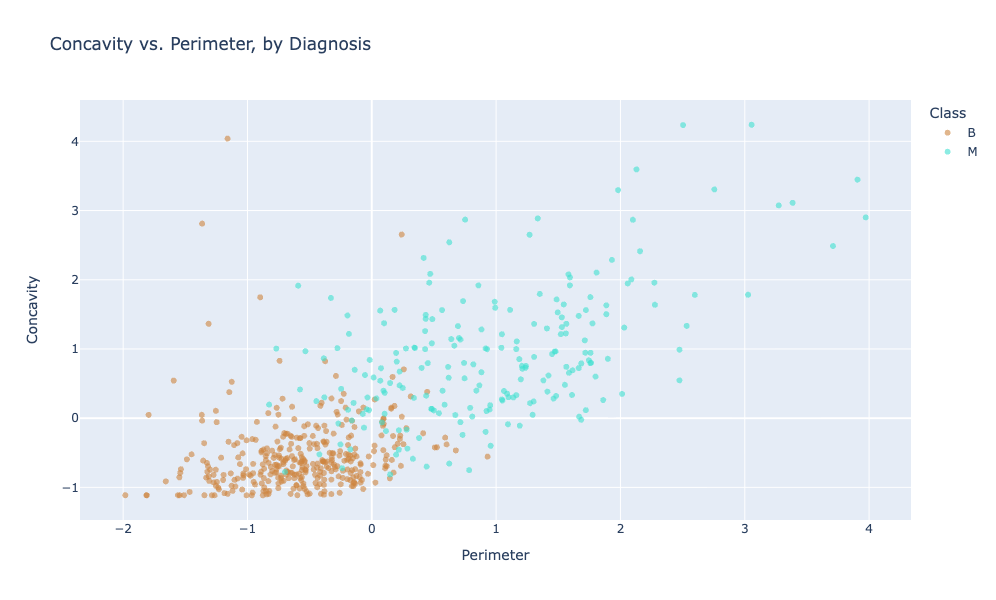

In [23]:
fig = px.scatter(cancer, x = "Perimeter", y = "Concavity", color = "Class",
                 color_discrete_map = {"B": "peru", "M": "turquoise"},
                 category_orders = {"Class": ["B", "M"]},
                 opacity = 0.6,
                 title = "Concavity vs. Perimeter, by Diagnosis",
                 height = 600)
fig.show()

Return to our new patient with a perimeter of 0.5. We predicted *malignant* using perimeter alone. Suppose we now also learn that this patient's **concavity is -0.4**, a little *below* average. Does that change our prediction? To find out, we need to run k-NN with **two** explanatory variables. The only thing we need is a way to measure *distance* between two patients when each is described by two numbers.

### Distance in Two Dimensions

In the scatter plot above, each patient is a point. The most natural distance between two points is the **straight-line distance** you'd measure with a ruler. Something like this is visualized below. 

<div style="text-align: center;">
  <img src="https://raw.githubusercontent.com/ntstevens/DATSC101/refs/heads/main/images/knn_2d.svg" alt="global_warming" width = 275/>
</div>

The calculation of the straight-line-distance is based on the Pythagorean theorem, where the straight lines above are treated like hypotenuses of right angle triangles. The graphic below illustrates this.

<div style="text-align: center;">
  <img src="https://raw.githubusercontent.com/ntstevens/DATSC101/refs/heads/main/images/pythagorean_thm.svg" alt="global_warming" width = 600/>
</div>

So, the calculation for distance between any two points is: $$d = \sqrt{(\text{difference in perimeter})^2 + (\text{difference in concavity})^2}$$

With a single variable, this formula simplifies to the absolute difference we used before. **Everything else about k-NN stays exactly the same**: find the $k$ patients with the smallest distance, and let them vote.

### 💻 Interactive: Build Your Intuition for k-NN Classification

Before we ask Python to do this for us, let's play with the idea. The app below lets you see how k-NN makes classifications and what happens when you change $k$. This time, focus on the "2-D: Perimeter & Concavity Tab".

> **If the app doesn't display below**, open it in its own browser tab: [https://nathaniel-t-stevens.shinyapps.io/knn_classification_app/](https://nathaniel-t-stevens.shinyapps.io/knn_classification_app/)



In [24]:
%%html
<div style="text-align: center;">
<iframe src="https://nathaniel-t-stevens.shinyapps.io/knn_classification_app/" width="100%" height="850" frameborder="0"></iframe>
</div>

### By Hand

Let's first do this by hand and classify our new patient (perimeter = 0.5, concavity = -0.4) with $k = 5$. 

Compute the two-dimensional distance from the new patient to every patient in the data, and keep the five closest:

In [41]:
new_perimeter = 0.5
new_concavity = -0.4

by_hand = cancer.copy()
by_hand["Distance"] = np.sqrt((by_hand["Perimeter"] - new_perimeter) ** 2 +
                              (by_hand["Concavity"] - new_concavity) ** 2)

neighbours = by_hand.sort_values(by = "Distance").head(5)
neighbours[["Perimeter", "Concavity", "Class", "Distance"]]

,Perimeter,Concavity,Class,Distance
406,0.507468,-0.423976,B,0.025113
508,0.523930,-0.420715,B,0.031651
363,0.602123,-0.378567,B,0.104347
375,0.589776,-0.279596,B,0.150190
182,0.379891,-0.286871,M,0.164998


In [26]:
neighbours["Class"].value_counts()

Class
B    4
M    1
Name: count, dtype: int64

Now **four** of the five nearest neighbours are benign and only **one** is malignant. Taking concavity into account **changes the prediction** from *malignant* to *benign*. A patient with a slightly above-average perimeter but a smoother-than-typical outline looks more like the benign patients.

### With `scikit-learn`

Next, let's automate this with the familiar `scikit-learn` recipe. The only change relative to what we've done before is that the input `X`, now has two columns.

In [44]:
X2 = cancer[["Perimeter", "Concavity"]]

knn5_2d = KNeighborsClassifier(n_neighbors = 5).fit(X2, y)

new_patient = pd.DataFrame({"Perimeter": [new_perimeter], "Concavity": [new_concavity]})

print("Predicted class:", knn5_2d.predict(new_patient))

Predicted class: [0]


It matches our by-hand calculation.

### Decision Boundary

As we saw in the interactive app, with two explanatory variables, we can visualize the **decision boundary**. It partitions the plane highlighting which (`Perimeter`, `Concavity`) values will be classified as benign vs. malignant. The decision boundary for $k=15$ is shown below.

In [28]:
knn15_2d = KNeighborsClassifier(n_neighbors = 15).fit(X2, y)
new_X = []
for new_perimeter in np.arange(-2, 4.1, 0.05):
    for new_concavity in np.arange(-1.1, 4.4, 0.05):
        new_X.append(pd.DataFrame({"Perimeter":[new_perimeter], "Concavity":[new_concavity]}))
        
new_X = pd.concat(new_X)
pred = knn15_2d.predict(new_X)

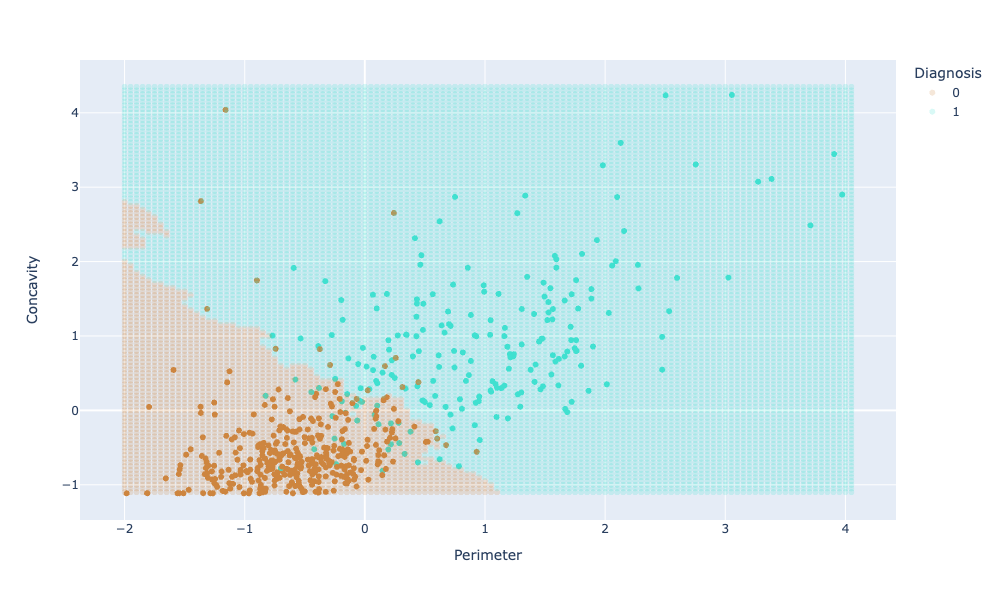

In [29]:
fig = px.scatter(x = new_X["Perimeter"], y = new_X["Concavity"], color = pred.astype(str),
           color_discrete_map = {"0": "peru", "1": "turquoise"},
           labels = {"x":"Perimeter", "y":"Concavity", "color":"Diagnosis"}, height = 600, opacity = 0.2)
import plotly.graph_objects as go
color_map = {"B": "peru", "M": "turquoise"}
fig.add_trace(go.Scatter(x = cancer["Perimeter"], y = cancer["Concavity"], 
              mode = "markers", showlegend=False,
              marker = dict(color = [color_map[val] for val in cancer["Class"]])))
fig.update_traces(name="Diagnosis", selector={"0":"Benign"})

**What do we see?**

* The decision boundary is not a simple cut-off value, it's a *curve* (or several) that carves the plane into a "predict benign" region and a "predict malignant" region.
* The model predicts malignant for large perimeters, *and* for moderate perimeters with high concavity. It predicts benign for small perimeters, *and* for moderate perimeters with low concavity.
* The boundary is *flexible*: it bends wherever the data tell it to, rather than following a pre-specified shape. That is one of the real strengths of k-NN.
* With the observed data overlaid, we also get a sence for the performance of the model; misclassifications are clearly identified (a brown point in the turquoise region and a turquoise point in the brown region).

### Does the Second Variable Help?

Let's compare the performance of the perimeter-only model with the perimeter-and-concavity model, for $k = 5$ and $k = 15$.

In [46]:
rows = []
for k in [5, 15]:
    models = {"Perimeter only": X,
              "Perimeter + Concavity": X2}
    for name, features in models.items():
        model = KNeighborsClassifier(n_neighbors = k).fit(features, y)
        summary = classification_summary(y, model.predict(features))
        summary["Model"] = name
        summary["k"] = k
        rows.append(summary)

pd.DataFrame(rows).set_index(["k", "Model"]).round(3)

TP  FN  FP   TN  Accuracy  Sensitivity  Specificity
k  Model                                                                      
5  Perimeter only         179  33  15  342     0.916        0.844        0.958
   Perimeter + Concavity  189  23  13  344     0.937        0.892        0.964
15 Perimeter only         170  42  17  340     0.896        0.802        0.952
   Perimeter + Concavity  185  27  17  340     0.923        0.873        0.952

With concavity added, accuracy, sensitivity, and specificity improve for both values of $k$. The improvement is modest, but we see an improvement nonetheless. So, `Concavity` carries information that `Perimeter` doesn't, but there is still overlap between the groups.

---

#### ACTIVITY 💻: Fit a 5-NN model using **Perimeter** and **Texture**. Compute its accuracy, sensitivity and specificity. Is it better or worse than the Perimeter + Concavity model with $k = 5$? What does that tell you about which variables are useful?

<details>
<summary><b>Show Solution</b></summary>

```python
X_pt = cancer[["Perimeter", "Texture"]]

knn5_pt = KNeighborsClassifier(n_neighbors = 5).fit(X_pt, y)
classification_summary(y, knn5_pt.predict(X_pt))
```

Compare the result to the Perimeter + Concavity ($k = 5$) row of the table above. Not every variable is equally useful: some bring a lot of new information about the diagnosis, and others bring little.

</details>

---

### Beyond Two Variables

What if we used **more** variables? We can't draw a picture with ten axes, but k-NN doesn't care. With $p$ explanatory variables, the distance formula just gets $p$ terms under the square root:

$$d = \sqrt{(\text{difference in variable 1})^2 + (\text{difference in variable 2})^2 + \cdots + (\text{difference in variable } p)^2}$$

and the neighbours vote exactly as before. Let's try using **all ten** measurements:

In [31]:
features = ["Radius", "Texture", "Perimeter", "Area", "Smoothness",
            "Compactness", "Concavity", "Concave_Points", "Symmetry", "Fractal_Dimension"]

X_all = cancer[features]

knn15_all = KNeighborsClassifier(n_neighbors = 15).fit(X_all, y)
classification_summary(y, knn15_all.predict(X_all))

{'TP': 194,
 'FN': 18,
 'FP': 11,
 'TN': 346,
 'Accuracy': 0.9490333919156415,
 'Sensitivity': 0.9150943396226415,
 'Specificity': 0.969187675070028}

With all ten measurements, the 15-NN model reaches an accuracy of about 95%, a sensitivity of about 91.5%, and specificity of about 97%. This is an improvement to both 15-NN models we fit previously. This will often be the case: **predictive performance improves with more data.** 

However, these quantifications of predictive performance are calculated with the same data used to fit the model. It would be wise to evaluate predictive performance on data the model hasn't seen yet.

---
---

## Limitations of k-NN and Questions to Carry Forward

k-NN classification (and numeric prediction) is simple, intuitive and flexible, but it has some drawbacks we've now experience:

* **The predictions depend on a value of $k$** that's hard to choose. Small $k$ gives jumpy predictions that chase individual patients; large $k$ gives smooth predictions that can ignore real structure (at the extreme, $k = 569$ predicted "benign" for everyone).
* **It has to carry around the whole data set** to make a prediction, and it gives no compact summary of *how* the explanatory variables relate to the diagnosis.

And we've raised some questions that we'll return to:

* How should we choose $k$?
* If a model scores well on the data it was built from, will it do well on *new* patients?


---
---

## Summary of Useful Methods and Functions

| Code | What it does |
|---|---|
| `df["Malignant"] = (df["Class"] == "M").astype(int)` | Creates a 0/1 version of a categorical variable (1 = positive class). |
| `from sklearn.neighbors import KNeighborsClassifier` | Imports the k-NN method for classification. |
| `model = KNeighborsClassifier(n_neighbors = k)` | **Creates** a k-NN classifier that uses $k$ neighbours (choose $k$ odd to avoid ties). |
| `model.fit(X, y)` | **Fits** the model to explanatory variable(s) `X` (a data frame, with one or more columns) and a response `y` of class labels. |
| `model.predict(new_X)` | **Predicts** the class (the majority vote) for each row of `new_X`. |
| `confusion_matrix(y, predictions)` | Cross-tabulates actual vs. predicted classes: `[[TN, FP], [FN, TP]]`. |
| `accuracy_score(y, predictions)` | **Accuracy**: the proportion of correct predictions. |
| `recall_score(y, predictions)` | **Sensitivity**: the proportion of actual positives that were caught. |
| `recall_score(y, predictions, pos_label = 0)` | **Specificity**: the proportion of actual negatives that were correctly cleared. |

---
---

## Key Takeaways

* **Classification** is *prediction of a category*: the response is a *class*. **Binary classification** has two classes coded 0 and 1; the class coded 1 is the **positive class**, the outcome we're trying to detect. (In this course we handle only the binary case; *multi-class* classification has more than two classes.)
* **k-NN classification** works just like k-NN regression, except that the $k$ nearest neighbours take a **majority vote** instead of being averaged. The *proportion* of neighbours in the positive class tells us how lopsided the vote was.
* The **decision boundary** is where the model's prediction switches from one class to the other. With one variable it's a cut-off value; with two it's a curve in the plane.
* A classifier's performance is summarized with the **confusion matrix** of true/false positives and negatives, and three key measures:
    * **Accuracy** = $\frac{TP + TN}{TP + FN + TN + FP}$: the proportion of predictions that are correct,
    * **Sensitivity** = $\frac{TP}{TP + FN}$: the proportion of actual positives that are caught,
    * **Specificity** = $\frac{TN}{TN + FP}$: the proportion of actual negatives that are correctly cleared.
* **Accuracy can mislead**, especially when one class is more common than the other. Always compare it to the "always predict the most common class" baseline and report sensitivity and specificity.
* k-NN extends naturally from **one** explanatory variable to **two** and to **many**: only the distance formula changes (more terms), and the neighbours vote as before.

---
---